# Guidance × compositionality: when does guidance decide "which object gets which colour"?

**Question.** The *guidance interval* (applying guidance only in the middle of denoising) improves overall image quality,
but it switches guidance off at the beginning, exactly when the layout of the image is decided. Does it hurt object-colour association (*attribute binding*)?

**Notebook outline**
1. Settings, output folder, template prompts (our own dataset)
2. Home-made denoising loop with configurable guidance (CFG, interval, APG, "guidance off" windows)
3. Generation (automatic resume)
4. Automatic evaluator (OWL-ViT + CLIP) → `results.csv`
5. **Blind manual annotation** of ~60 images → evaluator/human agreement
6. Analysis: paired bootstrap, per-window curves, cost (NFE, time)

**How to use**
- **Run with `QUICK = True` first** (≈ 5–10 minutes) to check that everything works, then set `QUICK = False`.
- Runtime: *Runtime → Change runtime type → T4 GPU*.
- **Without Drive (`USE_DRIVE = False`)** everything lives on Colab's temporary disk. If the session is *recycled* (long disconnection, GPU quota), **everything is lost**. Run the "Backup" cell (at the bottom) after each major step and keep the zip on your computer.
- If the session stays alive, simply re-run the cells: anything that already exists is skipped.

## 1. Settings

In [ ]:
!pip -q install diffusers transformers accelerate scipy scikit-learn

import os, time, math, gc, re, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image

QUICK     = False    # True = quick test (4 prompts, 1 seed),set to False for real run.
RUN_EXTRA = False   # True = adds cfg_w4, cfg_w12, apg_w12 (+40 min) for hyper-parameter analysis
N_PROMPTS = 60
SEEDS     = [0, 1]
STEPS     = 20
MODEL_ID  = "stable-diffusion-v1-5/stable-diffusion-v1-5"
H = W = 512

USE_DRIVE = False   # False = Colab local disk (/content). True = Google Drive
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = "/content/drive/MyDrive"
else:
    BASE = "/content"
ROOT = f"{BASE}/guidance_binding" + ("_quick" if QUICK else "")
os.makedirs(f"{ROOT}/images", exist_ok=True)
os.makedirs(f"{ROOT}/figures", exist_ok=True)

assert torch.cuda.is_available(), "Enable the GPU: Runtime > Change runtime type > T4"
dev = "cuda"
print(torch.cuda.get_device_name(0), "| output folder:", ROOT)

Tesla T4 | output folder: /content/guidance_binding


## 2. Template prompts
`a {colour1} {object1} and a {colour2} {object2}`: 60 combinations drawn with a fixed seed (reproducible).

In [2]:
COLORS  = ["red", "blue", "green", "yellow", "purple", "orange"]
OBJECTS = ["car", "apple", "chair", "bicycle", "umbrella", "backpack", "cup", "book", "ball", "hat"]

def art(word):                       # "an orange", "a red"
    return "an" if word[0] in "aeiou" else "a"

rng = random.Random(123)
prompts, seen = [], set()
while len(prompts) < N_PROMPTS:
    o1, o2 = rng.sample(OBJECTS, 2)
    c1, c2 = rng.sample(COLORS, 2)
    if (c1, o1, c2, o2) in seen:
        continue
    seen.add((c1, o1, c2, o2))
    prompts.append(dict(pid=len(prompts), c1=c1, o1=o1, c2=c2, o2=o2,
                        text=f"{art(c1)} {c1} {o1} and {art(c2)} {c2} {o2}"))

if QUICK:
    prompts = prompts[:4]
SEEDS_RUN = [0] if QUICK else SEEDS
print(len(prompts), "prompts ×", len(SEEDS_RUN), "seed(s). Examples:", [p["text"] for p in prompts[:3]])

60 prompts × 2 seed(s). Examples: ['a red car and a yellow umbrella', 'a red umbrella and a yellow apple', 'a green ball and an orange hat']


## 3. Guidance configurations

| Name | Description |
|---|---|
| `cfg` | Standard CFG, w = 7.5 at every step (reference) |
| `interval` | CFG only for 25 % ≤ progress < 75 % (the "guidance interval" method) |
| `apg` | Adaptive Projected Guidance (our own implementation based on the paper) |
| `off_w0 … off_w4` | CFG everywhere **except** in one 20 % window of denoising where guidance is switched off |

In [3]:
CONFIGS = {
    "cfg":      dict(kind="cfg", scale=7.5),
    "interval": dict(kind="cfg", scale=7.5, on=(0.25, 0.75)),
    "apg":      dict(kind="apg", scale=7.5, eta=0.0, momentum=-0.5, norm_thr=0.0),
}
WINDOWS = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
for k, (a, b) in enumerate(WINDOWS):
    CONFIGS[f"off_w{k}"] = dict(kind="cfg", scale=7.5, off=(a, b))
if RUN_EXTRA:
    CONFIGS["cfg_w4"]   = dict(kind="cfg", scale=4.0)
    CONFIGS["cfg_w12"]  = dict(kind="cfg", scale=12.0)
    CONFIGS["apg_w12"]  = dict(kind="apg", scale=12.0, eta=0.0, momentum=-0.5, norm_thr=0.0)

def guidance_active(c, frac):
    # is guidance applied at this step?
    ok = True
    if "on" in c:
        ok = ok and (c["on"][0] <= frac < c["on"][1])
    if "off" in c:
        ok = ok and not (c["off"][0] <= frac < c["off"][1])
    return ok

print(list(CONFIGS))

['cfg', 'interval', 'apg', 'off_w0', 'off_w1', 'off_w2', 'off_w3', 'off_w4']


## 4. Model and home-made denoising loop
Stable Diffusion 1.5 in fp16 + DDIM (20 steps). We write the loop ourselves to control guidance at every step

In [4]:
import torch.nn.functional as F
from diffusers import StableDiffusionPipeline, DDIMScheduler

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, safety_checker=None, requires_safety_checker=False).to(dev)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

@torch.no_grad()
def encode(text):
    ids = pipe.tokenizer(text, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                         truncation=True, return_tensors="pt").input_ids.to(dev)
    return pipe.text_encoder(ids)[0]

class Momentum:
    def __init__(self, m):
        self.m, self.avg = m, 0
    def update(self, v):
        self.avg = v + self.m * self.avg
        return self.avg

def apg_guidance(x0_c, x0_u, scale, buf, eta, norm_thr):
    # Adaptive Projected Guidance applied to the x0 predictions (conditional / unconditional)
    diff = buf.update(x0_c - x0_u)
    if norm_thr > 0:
        n = diff.norm(p=2, dim=(1, 2, 3), keepdim=True)
        diff = diff * torch.clamp(norm_thr / (n + 1e-8), max=1.0)
    v1 = x0_c / x0_c.norm(p=2, dim=(1, 2, 3), keepdim=True).clamp_min(1e-8)
    par = (diff * v1).sum(dim=(1, 2, 3), keepdim=True) * v1      # component parallel to the conditional prediction
    orth = diff - par
    return x0_c + (scale - 1.0) * (orth + eta * par)

@torch.no_grad()
def generate(prompt, seed, cfgname, steps=STEPS):
    c = CONFIGS[cfgname]
    sched = pipe.scheduler
    sched.set_timesteps(steps, device=dev)
    cond, uncond = encode(prompt), encode("")
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn((1, 4, H // 8, W // 8), generator=g, device=dev, dtype=torch.float16) * sched.init_noise_sigma
    buf = Momentum(c.get("momentum", 0.0)) if c["kind"] == "apg" else None
    nfe = 0
    torch.cuda.synchronize(); t0 = time.time()
    for i, t in enumerate(sched.timesteps):
        frac = i / steps
        xin = sched.scale_model_input(x, t)
        eps_c = pipe.unet(xin, t, encoder_hidden_states=cond).sample; nfe += 1
        if not guidance_active(c, frac):
            eps = eps_c                                   # no guidance: a single network pass
        else:
            eps_u = pipe.unet(xin, t, encoder_hidden_states=uncond).sample; nfe += 1
            if c["kind"] == "cfg":
                eps = eps_u + c["scale"] * (eps_c - eps_u)
            else:                                         # APG: work in x0 space
                a = sched.alphas_cumprod[int(t)].to(dev, torch.float32)
                xf = x.float()
                x0c = (xf - (1 - a).sqrt() * eps_c.float()) / a.sqrt()
                x0u = (xf - (1 - a).sqrt() * eps_u.float()) / a.sqrt()
                x0g = apg_guidance(x0c, x0u, c["scale"], buf, c["eta"], c["norm_thr"])
                eps = ((xf - a.sqrt() * x0g) / (1 - a).sqrt()).to(x.dtype)
        x = sched.step(eps, t, x).prev_sample
    img = pipe.vae.decode(x / pipe.vae.config.scaling_factor).sample
    torch.cuda.synchronize(); dt = time.time() - t0
    arr = (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()[0]
    return Image.fromarray((arr * 255).round().astype("uint8")), nfe, dt

# speed test (the first call is a warm-up and is not counted)
generate(prompts[0]["text"], 0, "cfg")
for cn in ["cfg", "interval", "apg"]:
    _, nfe, dt = generate(prompts[0]["text"], 0, cn)
    print(f"{cn:9s} NFE={nfe}  time={dt:.1f}s")
n_img = len(CONFIGS) * len(prompts) * len(SEEDS_RUN)
print(f"\n{n_img} images to generate in total.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

cfg       NFE=40  time=3.6s
interval  NFE=30  time=2.8s
apg       NFE=40  time=3.7s

960 images to generate in total.


## 5. Generation (automatic resume)
Each image is written to the output folder. If the session drops (but is not recycled), simply re-run this cell.
Order: `cfg`, windows, `interval`, `apg` (most important first).

In [6]:
LOG = f"{ROOT}/gen_log.csv"
log = pd.read_csv(LOG) if os.path.exists(LOG) else pd.DataFrame(columns=["config", "pid", "seed", "nfe", "time"])

def img_path(cfgname, pid, seed):
    return f"{ROOT}/images/{cfgname}/{int(pid):03d}_s{int(seed)}.png"

ORDER = ["cfg"] + [f"off_w{k}" for k in range(len(WINDOWS))] + ["interval", "apg"] + \
        [c for c in CONFIGS if c not in ["cfg", "interval", "apg"] and not c.startswith("off_w")]

t_start = time.time(); n_new = 0
for cn in ORDER:
    os.makedirs(f"{ROOT}/images/{cn}", exist_ok=True)
    for p in prompts:
        for s in SEEDS_RUN:
            path = img_path(cn, p["pid"], s)
            if os.path.exists(path):
                continue
            img, nfe, dt = generate(p["text"], s, cn)
            img.save(path)
            log.loc[len(log)] = [cn, p["pid"], s, nfe, dt]
            n_new += 1
    log.to_csv(LOG, index=False)
    print(f"{cn:9s} done | {n_new} new images | {(time.time()-t_start)/60:.1f} min elapsed")

cfg       done | 120 new images | 8.7 min elapsed
off_w0    done | 240 new images | 16.4 min elapsed
off_w1    done | 360 new images | 24.2 min elapsed
off_w2    done | 480 new images | 31.9 min elapsed
off_w3    done | 600 new images | 39.7 min elapsed
off_w4    done | 720 new images | 47.4 min elapsed
interval  done | 840 new images | 54.0 min elapsed
apg       done | 960 new images | 62.5 min elapsed


Quick visual check: same prompt and same seed for every configuration.

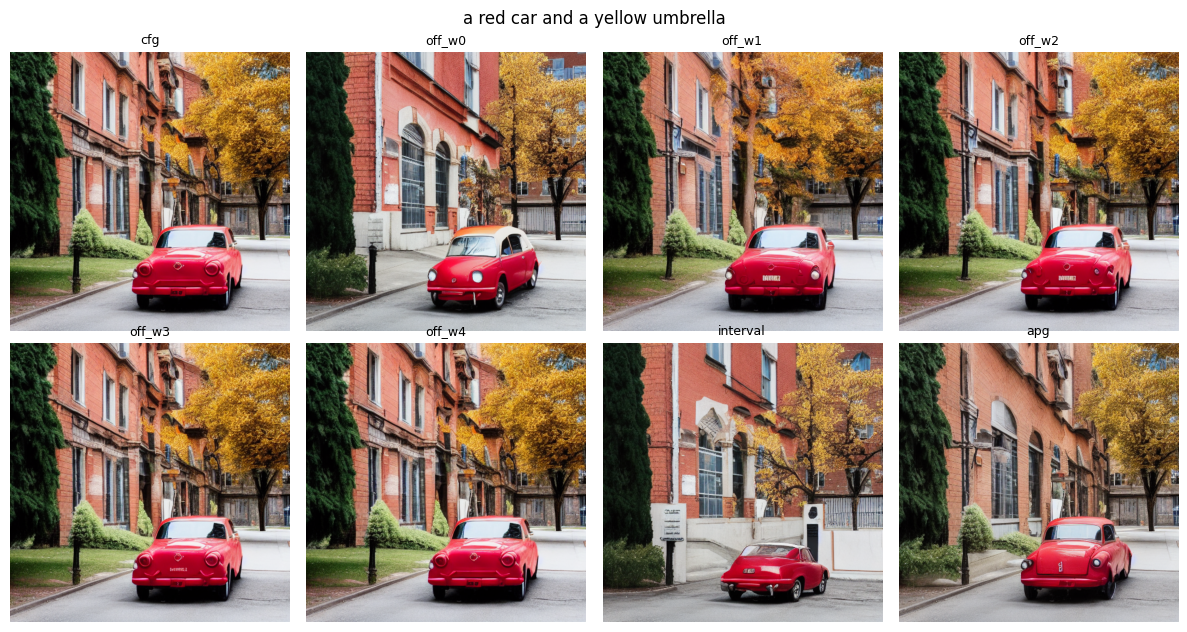

In [8]:
pid, seed = prompts[0]["pid"], SEEDS_RUN[0]
names = [c for c in ORDER if os.path.exists(img_path(c, pid, seed))]
fig, axes = plt.subplots(2, math.ceil(len(names) / 2), figsize=(3 * math.ceil(len(names) / 2), 6.4))
for ax in axes.ravel():
    ax.axis("off")
for ax, cn in zip(axes.ravel(), names):
    ax.imshow(Image.open(img_path(cn, pid, seed))); ax.set_title(cn, fontsize=9)
fig.suptitle(prompts[0]["text"]); plt.tight_layout(); plt.show()

## 6. Automatic evaluator
- **OWL-ViT** looks for each object (box + score). An object counts as "present" if its score ≥ 0.10.
- **CLIP** classifies the colour of each box among the 6 colours (prompt: "a photo of a {colour} {object}").
- `bind_ok` = both objects present **and** each one has the right colour. `swapped` = colours exchanged.
- `clip_score` = CLIP image/full-prompt similarity (×100), a general text-alignment metric.

This evaluator is imperfect, hence the manual validation below

In [9]:
# free the GPU: Stable Diffusion is no longer needed
del pipe; gc.collect(); torch.cuda.empty_cache()

from transformers import OwlViTProcessor, OwlViTForObjectDetection, CLIPModel, CLIPProcessor
owl_proc = OwlViTProcessor.from_pretrained("google/owlvit-base-patch32")
owl = OwlViTForObjectDetection.from_pretrained("google/owlvit-base-patch32").to(dev).eval()
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
DET_THR = 0.10

@torch.no_grad()
def clip_logits(images, texts):
    inp = clip_proc(text=texts, images=images, return_tensors="pt", padding=True).to(dev)
    return clip(**inp).logits_per_image.float().cpu()          # (n_images, n_texts), = cosine × 100

@torch.no_grad()
def detect(img, o1, o2):
    inp = owl_proc(text=[[f"a photo of a {o1}", f"a photo of a {o2}"]], images=img, return_tensors="pt").to(dev)
    out = owl(**inp)
    probs = out.logits[0].sigmoid().float().cpu()               # (n_boxes, 2)
    boxes = out.pred_boxes[0].float().cpu()                     # (cx, cy, w, h) normalised (square images)
    Wd, Hd = img.size
    res = []
    for k in range(2):
        j = int(probs[:, k].argmax()); s = float(probs[j, k])
        cx, cy, bw, bh = boxes[j].tolist()
        box = (max(0, int((cx - bw / 2) * Wd)), max(0, int((cy - bh / 2) * Hd)),
               min(Wd, int((cx + bw / 2) * Wd)), min(Hd, int((cy + bh / 2) * Hd)))
        res.append((s, box))
    return res

def evaluate_image(img, p):
    (s1, b1), (s2, b2) = detect(img, p["o1"], p["o2"])
    det1, det2 = s1 >= DET_THR, s2 >= DET_THR
    preds = []
    for b, o in [(b1, p["o1"]), (b2, p["o2"])]:
        if b[2] - b[0] < 4 or b[3] - b[1] < 4:
            preds.append(None); continue
        lg = clip_logits([img.crop(b)], [f"a photo of a {c} {o}" for c in COLORS])[0]
        preds.append(COLORS[int(lg.argmax())])
    presence = det1 and det2
    col1, col2 = det1 and preds[0] == p["c1"], det2 and preds[1] == p["c2"]
    return dict(det1=det1, det2=det2, s1=s1, s2=s2, pred1=preds[0], pred2=preds[1],
                presence=presence, col1_ok=col1, col2_ok=col2, bind_ok=presence and col1 and col2,
                swapped=presence and preds[0] == p["c2"] and preds[1] == p["c1"],
                clip_score=float(clip_logits([img], [p["text"]])[0, 0]))

RES = f"{ROOT}/results.csv"
res = pd.read_csv(RES) if os.path.exists(RES) else pd.DataFrame()
done = set(zip(res.config, res.pid, res.seed)) if len(res) else set()
rows = []
for cn in ORDER:
    for p in prompts:
        for s in SEEDS_RUN:
            if (cn, p["pid"], s) in done or not os.path.exists(img_path(cn, p["pid"], s)):
                continue
            r = evaluate_image(Image.open(img_path(cn, p["pid"], s)).convert("RGB"), p)
            rows.append(dict(config=cn, pid=p["pid"], seed=s, **r))
if rows:
    res = pd.concat([res, pd.DataFrame(rows)], ignore_index=True)
    res.to_csv(RES, index=False)
print(len(res), "images evaluated")
print(res.groupby("config")[["presence", "bind_ok", "swapped", "clip_score"]].mean().round(3))

preprocessor_config.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

... (12 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

960 images evaluated
          presence  bind_ok  swapped  clip_score
config                                          
apg          0.350    0.133    0.008      32.105
cfg          0.400    0.117    0.025      32.582
interval     0.367    0.058    0.050      31.204
off_w0       0.358    0.050    0.025      31.732
off_w1       0.375    0.117    0.008      32.056
off_w2       0.350    0.108    0.025      32.498
off_w3       0.383    0.092    0.025      32.530
off_w4       0.392    0.100    0.025      32.548


## 7. Blind manual annotation (60 images)

We draw 60 images (20 `cfg`, 20 `interval`+`apg`, 20 from the `off_w*` windows), half judged "correct" by the evaluator and half judged "failed".
**You see neither the configuration nor the evaluator's verdict.** For each image, click the button that matches what you see
(object 1 = first object named in the prompt):

| Button | Meaning |
|---|---|
| ✅ Both present, colours correct | both objects are there **and** each colour is on the right object |
| 🎨 Both present, colours wrong / mixed | both objects are there but colours are swapped, mixed or wrong |
| Only *object 1* / Only *object 2* | only one of the two objects is visible |
| ❌ Neither | none of the two objects is visible |

Progress is saved after every click, so you can stop and resume (re-run the two cells below). **Undo** cancels the last answer.

In [10]:
# Setup: draw the images to annotate, reload previous answers, define saving helpers
res = pd.read_csv(RES)
N_PER_GROUP = 2 if QUICK else 20
groups = {
    "cfg": ["cfg"],
    "interval_apg": ["interval", "apg"],
    "off": [c for c in res.config.unique() if c.startswith("off_w")],
}
def stratified(df, n):
    pos, neg = df[df.bind_ok], df[~df.bind_ok]
    k = n // 2
    return pd.concat([pos.sample(min(k, len(pos)), random_state=0), neg.sample(min(n - k, len(neg)), random_state=0)])

samp = pd.concat([stratified(res[res.config.isin(v)], N_PER_GROUP) for v in groups.values()])
items = samp.sample(frac=1, random_state=1).reset_index(drop=True)   # random order = blind annotation
ANN = f"{ROOT}/manual_annotations.csv"

# reload answers already saved (resume)
answers = {}
if os.path.exists(ANN):
    old = pd.read_csv(ANN)
    key2i = {(r.config, int(r.pid), int(r.seed)): i for i, r in items.iterrows()}
    for _, r in old.iterrows():
        i = key2i.get((r.config, int(r.pid), int(r.seed)))
        if i is not None:
            answers[i] = ("y" if r.h_obj1 else "n") + ("y" if r.h_obj2 else "n") + ("y" if r.h_bind else "n")

def save_answers():
    rows = []
    for i, c in sorted(answers.items()):
        r = items.iloc[i]
        rows.append([r.config, int(r.pid), int(r.seed), c[0] == "y", c[1] == "y", c[2] == "y"])
    pd.DataFrame(rows, columns=["config", "pid", "seed", "h_obj1", "h_obj2", "h_bind"]).to_csv(ANN, index=False)

def next_index():
    for i in range(len(items)):
        if i not in answers:
            return i
    return None

print(len(items), "images to annotate |", len(answers), "already annotated")

60 images to annotate | 0 already annotated


In [11]:
# One-click annotation interface
import ipywidgets as widgets
from IPython.display import display, clear_output

CODES = ["yyy", "yyn", "ynn", "nyn", "nnn"]
buttons = [widgets.Button(layout=widgets.Layout(width="auto", height="40px")) for _ in CODES]
undo = widgets.Button(description="↩ Undo last", button_style="warning", layout=widgets.Layout(width="auto", height="40px"))
out = widgets.Output()
last = []                                           # history of annotated indices, for undo

def render():
    i = next_index()
    with out:
        clear_output(wait=True)
        if i is None:
            for b in buttons:
                b.disabled = True
            print(f"All done: {len(answers)}/{len(items)} images annotated. Saved to {ANN}")
            return
        r = items.iloc[i]; p = prompts[int(r.pid)]
        o1, o2 = p["o1"], p["o2"]
        labels = ["✅ Both present, colours correct", "🎨 Both present, colours wrong / mixed",
                  f"Only {o1}", f"Only {o2}", "❌ Neither"]
        for b, l in zip(buttons, labels):
            b.description = l; b.disabled = False
        display(Image.open(img_path(r.config, r.pid, r.seed)).resize((420, 420)))
        print(f"[{len(answers) + 1}/{len(items)}]  {p['text']}   (object 1 = {o1}, object 2 = {o2})")

def make_handler(code):
    def handler(_):
        i = next_index()
        if i is None:
            return
        answers[i] = code; last.append(i); save_answers(); render()
    return handler

def on_undo(_):
    if last:
        answers.pop(last.pop(), None); save_answers(); render()

for b, c in zip(buttons, CODES):
    b.on_click(make_handler(c))
undo.on_click(on_undo)

display(widgets.VBox([out, widgets.HBox(buttons[:3]), widgets.HBox(buttons[3:] + [undo])]))
render()

### Agreement: automatic evaluator ↔ human

In [12]:
from sklearn.metrics import cohen_kappa_score

ann = pd.read_csv(ANN); res = pd.read_csv(RES)
m = ann.merge(res, on=["config", "pid", "seed"])
print(f"n = {len(m)} annotated images\n")
for h, e, label in [("h_obj1", "det1", "object 1 present"), ("h_obj2", "det2", "object 2 present"), ("h_bind", "bind_ok", "binding correct")]:
    a, b = m[h].astype(bool), m[e].astype(bool)
    acc = np.mean(a == b); half = 1.96 * math.sqrt(acc * (1 - acc) / len(m))
    print(f"{label:18s} agreement = {acc:.2f} ± {half:.2f} | kappa = {cohen_kappa_score(a, b):.2f} | "
          f"false positives = {int((~a & b).sum())} | false negatives = {int((a & ~b).sum())}")

print("\nBinding agreement per group of configurations:")
m["group"] = m.config.map(lambda c: "off" if c.startswith("off_w") else ("interval_apg" if c in ("interval", "apg") else "cfg"))
print(m.groupby("group").apply(lambda d: pd.Series(dict(n=len(d), agreement=np.mean(d.h_bind.astype(bool) == d.bind_ok.astype(bool))))).round(2))

n = 60 annotated images

object 1 present   agreement = 0.95 ± 0.06 | kappa = 0.64 | false positives = 2 | false negatives = 1
object 2 present   agreement = 0.93 ± 0.06 | kappa = 0.85 | false positives = 4 | false negatives = 0
binding correct    agreement = 0.82 ± 0.10 | kappa = 0.63 | false positives = 8 | false negatives = 3

Binding agreement per group of configurations:
                 n  agreement
group                        
cfg           20.0       0.80
interval_apg  20.0       0.85
off           20.0       0.80


/tmp/ipykernel_1009/1509266332.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(m.groupby("group").apply(lambda d: pd.Series(dict(n=len(d), agreement=np.mean(d.h_bind.astype(bool) == d.bind_ok.astype(bool))))).round(2))


## 8. Analysis
- 95 % CIs by **bootstrap over prompts** (the 2 seeds of a prompt are averaged, then prompts are resampled).
- **Paired** differences against `cfg`: same prompts, same seeds.

In [13]:
res = pd.read_csv(RES)
for col in ["presence", "bind_ok", "swapped"]:
    res[col] = res[col].astype(float)
agg = res.groupby(["config", "pid"])[["presence", "bind_ok", "swapped", "clip_score"]].mean().reset_index()
B = 2000

def piv(metric):
    return agg.pivot(index="pid", columns="config", values=metric)

def boot_mean(x, seed=0):
    x = np.asarray(x, float); r = np.random.RandomState(seed)
    ms = x[r.randint(0, len(x), (B, len(x)))].mean(1)
    return x.mean(), np.percentile(ms, 2.5), np.percentile(ms, 97.5)

def boot_diff(a, b, seed=0):
    return boot_mean(np.asarray(a, float) - np.asarray(b, float), seed)

rows = []
for metric in ["bind_ok", "presence", "swapped", "clip_score"]:
    P = piv(metric)
    for cn in P.columns:
        mu, lo, hi = boot_mean(P[cn].values)
        d = boot_diff(P[cn].values, P["cfg"].values) if cn != "cfg" else (0.0, 0.0, 0.0)
        rows.append(dict(metric=metric, config=cn, mean=mu, lo=lo, hi=hi, d_vs_cfg=d[0], d_lo=d[1], d_hi=d[2]))
summary = pd.DataFrame(rows)
summary.to_csv(f"{ROOT}/summary.csv", index=False)
print(summary[summary.metric == "bind_ok"].round(3).to_string(index=False))

 metric   config  mean    lo    hi  d_vs_cfg   d_lo   d_hi
bind_ok      apg 0.133 0.075 0.200     0.017 -0.025  0.058
bind_ok      cfg 0.117 0.067 0.175     0.000  0.000  0.000
bind_ok interval 0.058 0.025 0.100    -0.058 -0.125  0.000
bind_ok   off_w0 0.050 0.017 0.092    -0.067 -0.133 -0.008
bind_ok   off_w1 0.117 0.058 0.175     0.000 -0.033  0.033
bind_ok   off_w2 0.108 0.058 0.167    -0.008 -0.025  0.000
bind_ok   off_w3 0.092 0.042 0.150    -0.025 -0.058  0.000
bind_ok   off_w4 0.100 0.050 0.158    -0.017 -0.042  0.000


### Figure 1: effect of switching guidance off in each time window

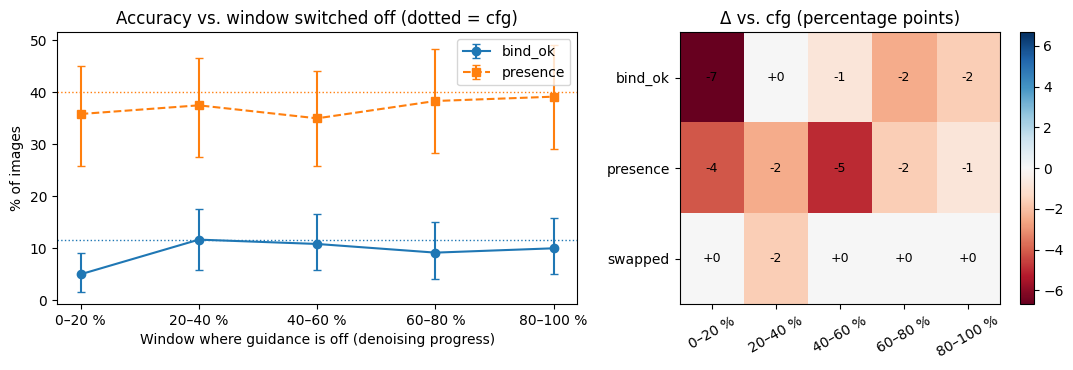

In [14]:
wins = [f"off_w{k}" for k in range(len(WINDOWS))]
labels = [f"{int(a * 100)}–{int(b * 100)} %" for a, b in WINDOWS]
S = summary.set_index(["metric", "config"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
for metric, style in [("bind_ok", "o-"), ("presence", "s--")]:
    y = np.array([S.loc[(metric, w), "mean"] for w in wins]) * 100
    lo = np.array([S.loc[(metric, w), "lo"] for w in wins]) * 100
    hi = np.array([S.loc[(metric, w), "hi"] for w in wins]) * 100
    ax.errorbar(range(len(wins)), y, yerr=[y - lo, hi - y], fmt=style, capsize=3, label=metric)
    base = S.loc[(metric, "cfg"), "mean"] * 100
    ax.axhline(base, ls=":", lw=1, color=ax.lines[-1].get_color())
ax.set_xticks(range(len(wins))); ax.set_xticklabels(labels)
ax.set_xlabel("Window where guidance is off (denoising progress)")
ax.set_ylabel("% of images"); ax.set_title("Accuracy vs. window switched off (dotted = cfg)"); ax.legend()

ax = axes[1]
metrics = ["bind_ok", "presence", "swapped"]
D = np.array([[S.loc[(m, w), "d_vs_cfg"] * 100 for w in wins] for m in metrics])
im = ax.imshow(D, cmap="RdBu", vmin=-np.abs(D).max(), vmax=np.abs(D).max(), aspect="auto")
ax.set_xticks(range(len(wins))); ax.set_xticklabels(labels, rotation=30); ax.set_yticks(range(len(metrics))); ax.set_yticklabels(metrics)
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        ax.text(j, i, f"{D[i, j]:+.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Δ vs. cfg (percentage points)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f"{ROOT}/figures/fig_windows.pdf", bbox_inches="tight"); plt.show()

### Figure 2: comparison of methods (cfg, interval, apg) and cost

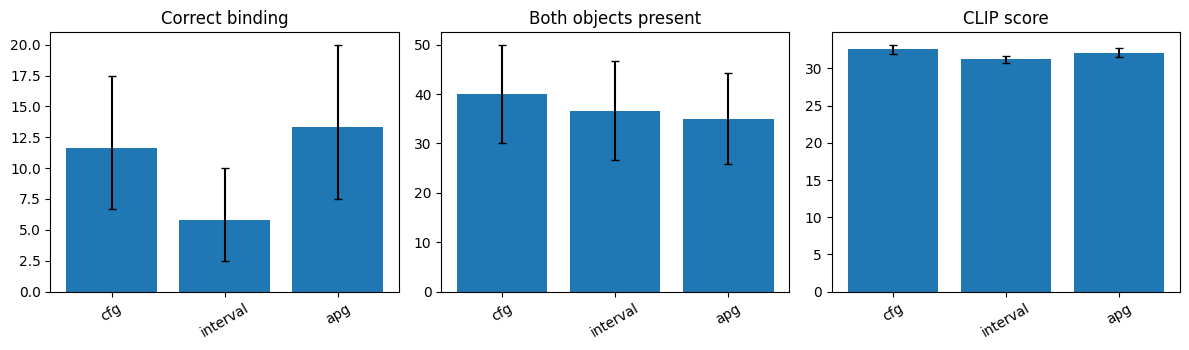

Paired differences vs. cfg (binding, percentage points, 95 % CI):
  config  d_vs_cfg  d_lo  d_hi
     apg       1.7  -2.5   5.8
interval      -5.8 -12.5   0.0
  off_w0      -6.7 -13.3  -0.8
  off_w1       0.0  -3.3   3.3
  off_w2      -0.8  -2.5   0.0
  off_w3      -2.5  -5.8   0.0
  off_w4      -1.7  -4.2   0.0

Cost per image:
           NFE  time_s  NFE_vs_cfg
config                            
apg       40.0    4.14        1.00
cfg       40.0    4.22        1.00
interval  30.0    3.16        0.75
off_w0    36.0    3.74        0.90
off_w1    36.0    3.74        0.90
off_w2    36.0    3.74        0.90
off_w3    36.0    3.74        0.90
off_w4    36.0    3.74        0.90


In [15]:
meths = [c for c in ["cfg", "interval", "apg", "cfg_w4", "cfg_w12", "apg_w12"] if c in set(summary.config)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, metric, title in zip(axes, ["bind_ok", "presence", "clip_score"], ["Correct binding", "Both objects present", "CLIP score"]):
    mu = np.array([S.loc[(metric, m), "mean"] for m in meths]); lo = np.array([S.loc[(metric, m), "lo"] for m in meths])
    hi = np.array([S.loc[(metric, m), "hi"] for m in meths])
    sc = 100 if metric != "clip_score" else 1
    ax.bar(meths, mu * sc, yerr=[(mu - lo) * sc, (hi - mu) * sc], capsize=3)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{ROOT}/figures/fig_methods.pdf", bbox_inches="tight"); plt.show()

print("Paired differences vs. cfg (binding, percentage points, 95 % CI):")
d = summary[(summary.metric == "bind_ok") & (summary.config != "cfg")].copy()
for c in ["d_vs_cfg", "d_lo", "d_hi"]:
    d[c] = (d[c] * 100).round(1)
print(d[["config", "d_vs_cfg", "d_lo", "d_hi"]].to_string(index=False))

log = pd.read_csv(LOG)
cost = log.groupby("config").agg(NFE=("nfe", "mean"), time_s=("time", "mean")).round(2)
cost["NFE_vs_cfg"] = (cost.NFE / cost.loc["cfg", "NFE"]).round(2)
print("\nCost per image:"); print(cost)
cost.to_csv(f"{ROOT}/cost.csv")

### Qualitative grid for the report
One prompt, one seed, all configurations (pick one case where `cfg` succeeds and one where it fails).

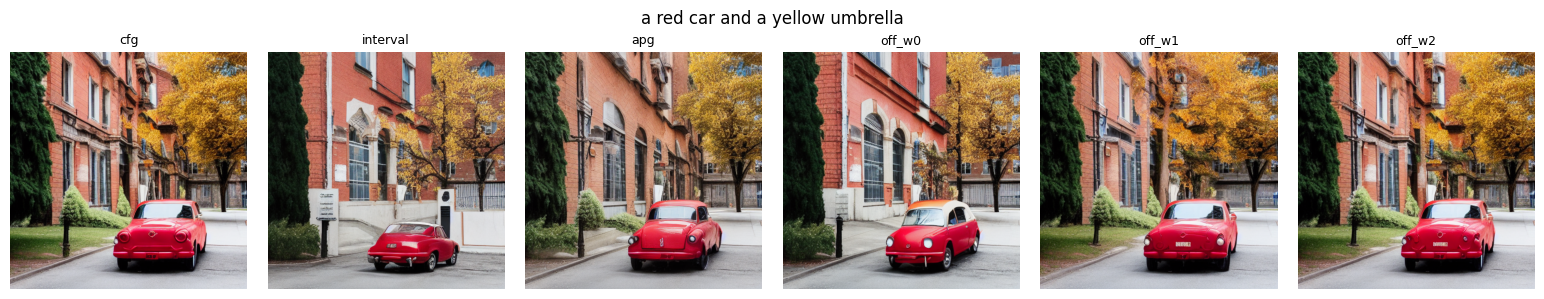

In [16]:
def show_grid(pid, seed=0, cfgs=("cfg", "interval", "apg", "off_w0", "off_w1", "off_w2"), save=None):
    fig, axes = plt.subplots(1, len(cfgs), figsize=(2.6 * len(cfgs), 3))
    for ax, cn in zip(axes, cfgs):
        ax.imshow(Image.open(img_path(cn, pid, seed))); ax.axis("off"); ax.set_title(cn, fontsize=9)
    fig.suptitle(prompts[pid]["text"], y=0.98); plt.tight_layout()
    if save: plt.savefig(f"{ROOT}/figures/{save}.pdf", bbox_inches="tight")
    plt.show()

show_grid(0, save="qualitative_pid0")

## Backup (copy into the GitHub repo / Overleaf)
- `results.csv`, `summary.csv`, `cost.csv`, `gen_log.csv`, `manual_annotations.csv`
- `figures/*.pdf` (vector graphics, include them directly in LaTeX)

Run the cell below after each major step (generation, evaluation, annotation, analysis).

In [17]:
import shutil
def backup(include_images=False):
    # light zip: CSVs + figures (+ images if requested, a few hundred MB)
    tmp = "/content/backup_light"
    shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
    for f in os.listdir(ROOT):
        fp = f"{ROOT}/{f}"
        if os.path.isfile(fp):
            shutil.copy(fp, tmp)
    if os.path.isdir(f"{ROOT}/figures"):
        shutil.copytree(f"{ROOT}/figures", f"{tmp}/figures")
    if include_images:
        shutil.copytree(f"{ROOT}/images", f"{tmp}/images")
    z = shutil.make_archive("/content/guidance_binding_backup", "zip", tmp)
    print("zip created:", z, f"({os.path.getsize(z)/1e6:.0f} MB)")
    try:
        from google.colab import files
        files.download(z)
    except Exception as e:
        print("Automatic download failed, use the Files panel on the left:", e)

backup(include_images=False)   # set to True to include all the images

zip created: /content/guidance_binding_backup.zip (1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>